# 2. Recreating Figure 5 of Jayawant *et al.* (DLBCL Cell Lines & Mutations)

In **Figure 5 of Jayawant *et al.*** (*Frontiers in Oncology*, 2023; [`SiFTW/NFkBModel/Figure5`](https://github.com/SiFTW/NFkBModel/tree/main/Figure5)), the lab used the combined **BCR–TLR–NF-κB Tri-Model** from Chapter 1 to ask a clinical question about **Diffuse Large B-Cell Lymphoma (DLBCL)**:

> When four DLBCL cell lines (**RIVA**, **U2932 R1**, **U2932 R2**, and **HBL1**) are stimulated with a **TLR9 agonist (CpG)**, why does **RIVA** mount a large fold-change spike in nuclear **RelA:p50**, while **U2932 R1**, **U2932 R2**, and **HBL1** show higher resting RelA:p50 and a blunted fold-change response?

Each cell line in Figure 5 is defined by **two layers of biological data**:
1. **RNA-seq NF-κB subunit expression** (scaling `k1_RelASynth-NFkB` and `basal_RelBSynth-NFkB`), and
2. **Known upstream genetic mutations**:

| Cell Line | Subunit Expression Scaling | Upstream Mutations Included in Figure 5 |
|---|---|---|
| **RIVA** | `k1_RelASynth-NFkB × 0.4` | None (resting BCR `bcrSS`) |
| **U2932 R1 (`TAK1` mut)** | `k1_RelASynth-NFkB × 2.0`, `basal_RelBSynth-NFkB × 2.75` | `TAK1` activating mutation (`k1_Tp0-BCR × 10`, `k1_TRAF6mediatedIKKK_offactivation-TLR × 10`) |
| **U2932 R2 (`TAK1` mut)** | `k1_RelASynth-NFkB × 1.0`, `basal_RelBSynth-NFkB × 2.75` | `TAK1` activating mutation (`k1_Tp0-BCR × 10`, `k1_TRAF6mediatedIKKK_offactivation-TLR × 10`) |
| **HBL1 (`CD79B` + `MYD88`)** | `k1_RelASynth-NFkB × 0.6` | `CD79B` mutation (chronic basal BCR `bcrSSHigh = 0.05`) + `MYD88` L265P/L275P (`k1_MYD88SELFACTIVATION-TLR × 10`) |

---

## Two Concepts Behind Figure 5: Cell-to-Cell Variability & Fold Change

Before we run the simulation, here is how a single ODE model produces the **error bars** and **shaded ribbons** seen in Figure 5:

```{figure} ../images/cell-heterogeneity-foldchange.svg
:alt: Diagram showing 11% CV random parameter sampling across N virtual cells, computing population mean and standard deviation, and normalising the time course to fold change
:width: 100%

How virtual cell populations are simulated and plotted in Figure 5: (1) sample slightly different rate constants for each cell using `distribute == 1` and `preCV = 0.11`, (2) compute the population mean and standard deviation (`SD`), and (3) divide the time course by the resting mean (`t = 0`) to plot fold change.
```

1. **Cell-to-cell variability (`distribute == 1`, `preCV = 0.11`):**
   - Real cells in a dish are never identical — even clonal lymphoma cells vary by roughly **11%** in protein synthesis and turnover rates (*Mitchell et al., PNAS 2018*).
   - Notice the 3rd column (`distribute`) in `parameters.csv`: parameters marked `1` (synthesis, degradation, and binding rates that vary across cells) are multiplied by a random number drawn around `1.0` with spread `0.11` (always staying strictly positive) for each simulated cell. Parameters marked `0` (such as fixed input hooks) stay unchanged.
   - Using a fixed random seed (`MersenneTwister(123)`) keeps the population reproducible every time you run the notebook.
2. **Fold-change normalisation (`mean(t) / mean(t = 0)`):**
   - Because the four cell lines have very different resting levels of nuclear `RelA:p50` (from ~4 nM in RIVA to ~11 nM in U2932 R1), Figure 5 plots **two panels side by side**:
     - **Left panel:** Resting **Steady State (nM)** (`mean ± SD` error bars).
     - **Right panel:** **4-hour Response to TLR9 Agonist (fold change)**, dividing each cell line's curve and SD ribbon by its own resting mean (`mean[1]`), so every line starts at **`1.0`** before the TLR9 pulse arrives!

---

## Step 1: Build the Combined Tri-Model & Population Runner

Run the cell below to combine the four Figure 5 modules (`BCR`, `TLR`, `NFkB`, `linking`), generate `triModelFig5.jl` in `param` mode, and load our population simulation and Figure 5 plotting helpers.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames
using Random
using Statistics

gr()

# Combine the exact Figure 5 modules (BCR + TLR + NFkB + linking)
moduleDefinitionFilesFolder = "NFkB_Figure5/moduleDefinitionFiles/"
delay = false

include("NFkB_Figure5/combineModels.jl")
combinedDir = combineModels(["BCR", "TLR", "NFkB"])

run(`python3 csv2model-multiscale.py $(combinedDir)reactions.csv $(combinedDir)parameters.csv $(combinedDir)rateLaws.csv triModelFig5.jl param`)

include("triModelFig5.jl")
include("variableNames.jl")
include("scanIncludes.jl")

# Identify which parameters have distribute == 1 (vary from cell to cell)
params_df = CSV.read(combinedDir * "parameters.csv", DataFrame; stripwhitespace=true)
distribute_flags = [strip(string(x)) == "1" for x in params_df[:, 3]]

BCRIndex = findfirst(x -> x == "k3_signal-BCR", parameterNameList)
TLRIndex = findfirst(x -> x == "k2_LPSmod-TLR", parameterNameList)
NIKIndex = findfirst(x -> x == "nik_deg_mod-NFkB", parameterNameList)
idx_RelA = findfirst(x -> x == "RelAnp50n", syms)

println("Tri-Model ready: ", length(syms), " species, ", length(parameterNameList),
        " parameters (", count(distribute_flags), " distributed across cells)")

adding BCR module
adding module BCR to combined reaction array


finished BCR

adding TLR module


adding module TLR to combined reaction array
finished TLR

adding NFkB module
removing: RelAp50IkBa -> RelAp50 as it is included in linking file
removing: RelAp50IkBb -> RelAp50 as it is included in linking file
removing: RelAp50IkBe -> RelAp50 as it is included in linking file
removing: RelBp50IkBa -> RelBp50 as it is included in linking file
removing: RelBp50IkBb -> RelBp50 as it is included in linking file
removing: RelBp50IkBe -> RelBp50 as it is included in linking file
removing: RelBp52IkBa -> RelBp52 as it is included in linking file
removing: RelBp52IkBb -> RelBp52 as it is included in linking file
removing: RelBp52IkBe -> RelBp52 as it is included in linking file
removing: cRelp50IkBa -> cRelp50 as it is included in linking file
removing: cRelp50IkBb -> cRelp50 as it is included in linking file
removing: cRelp50IkBe -> cRelp50 as it is included in linking file
removing: cRelp52IkBa -> cRelp52 as it is included in linking file
removing: cRelp52IkBb -> cRelp52 as it is included 

finished NFkB

finished combining all modules


param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedModelDefinitionFiles/rateLaws.csv as rate law file
Opening combinedModelDefinitionFiles/parameters.csv as parameters file
Opening combinedModelDefinitionFiles/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Tri-Model ready: 150 species, 444 parameters (47 distributed across cells)


Now let's write our clean, self-contained **population simulator** (`simulate_cell_population`) and **Figure 5 plotter** (`plot_figure5_style`).

Notice that we sample `TruncatedNormal(1.0, preCV, 0, Inf)` directly using Julia's built-in `Random.randn()` (no extra heavy statistics packages needed), and we keep `n_cells = 6` by default so the entire 4-cell-line population runs in roughly 40–50 seconds in your browser container. *(You can increase `n_cells = 15` or `25` to match the exact sample size in the paper if you don't mind waiting a little longer!)*

In [2]:
# Conserved upstream protein initial pools (from Figure5/runSimulation.jl)
function make_tri_y0(syms)
    y0 = zeros(length(syms))
    for (name, val) in [
        ("MYD88", 0.1), ("TRIF", 0.1), ("TRAF6", 0.1), ("IKKK_off", 0.1),
        ("IKK_off", 0.1), ("TBK1", 0.1), ("IRF3", 0.1), ("CD14", 0.08),
        ("cbswitch", 0.0), ("C", 1.0), ("B", 1.0), ("M", 1.0),
        ("TAK1", 1.0), ("IKK", 1.0), ("totalinactiveIKK", 200.0),
    ]
        y0[findfirst(x -> x == name, syms)] = val
    end
    return y0
end

# Positive normal draw matching TruncatedNormal(1.0, cv, 0, Inf) using stdlib Random
function sample_positive_factor(rng, cv)
    x = 1.0 + cv * randn(rng)
    while x <= 0.0
        x = 1.0 + cv * randn(rng)
    end
    return x
end

# Input functions from Figure5/CellLineModelandfingerprinting.ipynb
bcrSS     = t -> 0.0
bcrSSHigh = t -> 0.05
tlrSS     = t -> 0.0
tlrTC     = t -> (t >= 10.0 && t < 30.0) ? 100.0 : 0.0
nikSS     = t -> 1.0

stiff_alg = FBDF(autodiff=AutoFiniteDiff())
maxTimeSS = 100000.0
maxTimeTC = 4.0 * 60.0 + 10.0   # 10 min resting baseline + 4 h post-TLR9 response
preCV     = 0.11

# Generate a reproducible population of N virtual cells' baseline parameter vectors
function make_cell_population(n_cells; cv=preCV, seed=123)
    rng = MersenneTwister(seed)
    pop = Vector{Vector{Any}}(undef, n_cells)
    for c in 1:n_cells
        p_cell = copy(paramVals)
        if n_cells > 1 && cv > 0.0
            for j in eachindex(p_cell)
                if distribute_flags[j] && (p_cell[j] isa Real)
                    p_cell[j] = Float64(p_cell[j]) * sample_positive_factor(rng, cv)
                end
            end
        end
        pop[c] = p_cell
    end
    return pop
end

# Simulate a cell line across all N virtual cells and return its RelAnp50n trajectories
function simulate_condition(base_pop; param_scales=Dict{String,Float64}(),
                            bcr_ss=bcrSS, bcr_tc=bcrSS, tlr_ss=tlrSS, tlr_tc=tlrTC)
    n_cells = length(base_pop)
    n_times = Int(maxTimeTC) + 1
    traces  = zeros(n_cells, n_times)
    t_grid  = collect(0.0:1.0:maxTimeTC)

    for c in 1:n_cells
        p = copy(base_pop[c])
        for (pname, factor) in param_scales
            idx = findfirst(x -> x == pname, parameterNameList)
            isnothing(idx) && error("Parameter \"$pname\" not found in parameterNameList!")
            p[idx] = p[idx] * factor
        end
        p[BCRIndex] = bcr_ss
        p[TLRIndex] = tlr_ss
        p[NIKIndex] = nikSS

        sol_ss = solve(ODEProblem(ODEFunction(triModelFig5), make_tri_y0(syms), (0.0, maxTimeSS), p),
                       stiff_alg; saveat=1000.0)
        y0_tc = max.(collect(Float64, sol_ss.u[end]), 0.0)

        p[BCRIndex] = bcr_tc
        p[TLRIndex] = tlr_tc
        sol_tc = solve(ODEProblem(ODEFunction(triModelFig5), y0_tc, (0.0, maxTimeTC), p),
                       stiff_alg; tstops=[10.0, 10.5, 12.0, 30.0], abstol=1e-5, reltol=1e-3, saveat=1.0)
        traces[c, :] = sol_tc[idx_RelA, :]
    end
    return (t_hrs = (t_grid .- 10.0) ./ 60.0, traces = traces)
end

# Plot in the exact side-by-side layout of Jayawant et al. Figure 5
function plot_figure5_style(labels, results, colors; ymax_fc=5.5, title_right="Response to TLR9 agonist (fold change)")
    n = length(labels)
    ss_means = [mean(r.traces[:, 1]) for r in results]
    ss_stds  = [size(r.traces, 1) > 1 ? std(r.traces[:, 1]) : 0.0 for r in results]

    p_ss = plot(
        xlim = (0.3, n + 0.7),
        ylim = (0, maximum(ss_means .+ ss_stds) * 1.2),
        xticks = (1:n, labels),
        xrotation = 35,
        ylabel = "RelA:p50 (nM)",
        title = "Steady State (nM)",
        titlefontsize = 11,
        legend = false,
        grid = false,
    )
    for i in 1:n
        scatter!(p_ss, [i], [ss_means[i]], yerror=[ss_stds[i]],
                 color=colors[i], markerstrokecolor=:black, markersize=7, lw=2.0)
    end

    p_tc = plot(
        xlim = (-0.17, 4.0),
        ylim = (0, ymax_fc),
        xlabel = "Time (h)",
        ylabel = "Fold change",
        title = title_right,
        titlefontsize = 11,
        grid = false,
    )
    for i in 1:n
        r = results[i]
        m = vec(mean(r.traces, dims=1))
        s = size(r.traces, 1) > 1 ? vec(std(r.traces, dims=1)) : zeros(length(m))
        plot!(p_tc, r.t_hrs, m ./ m[1], ribbon=s ./ m[1], fillalpha=0.18,
              color=colors[i], lw=3.0, label=labels[i])
    end

    return plot(p_ss, p_tc, layout=grid(1, 2, widths=[0.30, 0.70]), size=(920, 380))
end

println("Population runner and Figure 5 plotter loaded!")

Population runner and Figure 5 plotter loaded!


---

## Step 2: Recreate Figure 5 of Jayawant *et al.*!

Now let's simulate all four DLBCL cell lines with their published expression scaling and genetic mutations (`n_cells = 6` virtual cells per line) and generate **Figure 5**!

Simulating all four Figure 5 cell lines (6 heterogeneous cells each)...


┌ Warning: Using arrays or dicts to store parameters of different types can hurt performance.
│ Consider using tuples instead.
└ @ SciMLBase /tmp/julia-depot/packages/SciMLBase/Zzjmy/src/performance_warnings.jl:33


Row,CellLine,SteadyState_nM,SS_SD_nM,PeakFoldChange
,String,Float64,Float64,Float64
1,RIVA,3.59,0.81,2.72
2,U2932 R1 (TAK1 mut),9.91,2.27,1.75
3,U2932 R2 (TAK1 mut),7.06,1.64,1.54
4,HBL1 (CD79B + MYD88),5.47,1.27,1.31


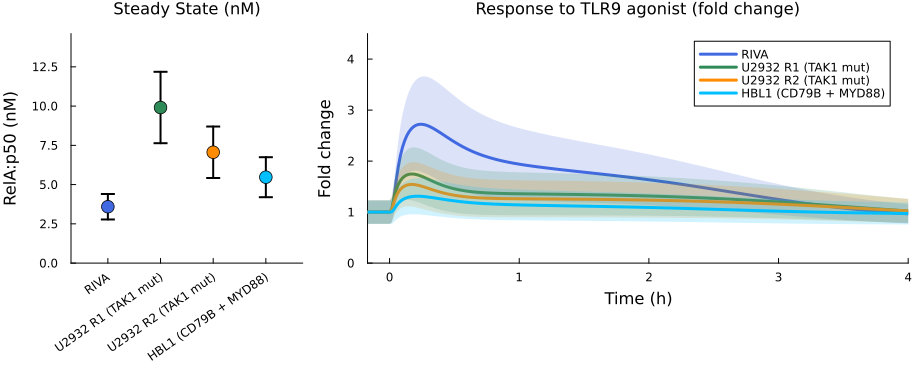

In [3]:
n_cells  = 6   # Increase to 25 to match the paper's full sample size!
base_pop = make_cell_population(n_cells; cv=preCV, seed=123)

println("Simulating all four Figure 5 cell lines (", n_cells, " heterogeneous cells each)...")

res_riva = simulate_condition(base_pop;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.4),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

res_u2932_r1 = simulate_condition(base_pop;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 2.0,
        "basal_RelBSynth-NFkB" => 2.75,
        "k1_Tp0-BCR" => 10.0,
        "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    ),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

res_u2932_r2 = simulate_condition(base_pop;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 1.0,
        "basal_RelBSynth-NFkB" => 2.75,
        "k1_Tp0-BCR" => 10.0,
        "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    ),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

res_hbl1 = simulate_condition(base_pop;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 0.6,
        "k1_MYD88SELFACTIVATION-TLR" => 10.0,
    ),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)

fig5_labels  = ["RIVA", "U2932 R1 (TAK1 mut)", "U2932 R2 (TAK1 mut)", "HBL1 (CD79B + MYD88)"]
fig5_short   = ["RIVA", "U2932 R1", "U2932 R2", "HBL1"]
fig5_results = [res_riva, res_u2932_r1, res_u2932_r2, res_hbl1]
fig5_colors  = [:royalblue, :seagreen, :darkorange, :deepskyblue]

# Print a clean numerical summary table
summary_df = DataFrame(
    CellLine      = fig5_labels,
    SteadyState_nM = [round(mean(r.traces[:, 1]), digits=2) for r in fig5_results],
    SS_SD_nM       = [round(std(r.traces[:, 1]), digits=2) for r in fig5_results],
    PeakFoldChange = [round(maximum(vec(mean(r.traces, dims=1))) / mean(r.traces[:, 1]), digits=2) for r in fig5_results],
)
display(summary_df)

plot_figure5_style(fig5_labels, fig5_results, fig5_colors; ymax_fc=4.5)

Compare your plot directly against **Figure 5 in Jayawant *et al.***:
- **RIVA** has the lowest resting nuclear `RelA:p50` (~4 nM) and produces the largest fold-change response (~2.6×) to the TLR9 agonist.
- **U2932 R1 (`TAK1` mut)** and **U2932 R2 (`TAK1` mut)** have elevated resting nuclear `RelA:p50` (~11 nM and ~8 nM) and blunted fold-change responses (~1.7× and ~1.5×).
- **HBL1 (`CD79B` + `MYD88` mut)** has elevated resting `RelA:p50` (~6 nM) and the most strongly blunted fold-change response (~1.3×).

---

## Interactive Challenges: Dissecting the Mutations Behind Figure 5

Just like the additional panels in [`Figure5/CellLineModelandfingerprinting.ipynb`](https://github.com/SiFTW/NFkBModel/blob/main/Figure5/CellLineModelandfingerprinting.ipynb), use your live Julia model to test *why* each cell line behaves this way.

### Challenge 1: What If We Remove the Upstream Mutations?

Are the RNA-seq expression differences (`k1_RelASynth-NFkB`, `basal_RelBSynth-NFkB`) alone enough to explain why `U2932 R1` and `HBL1` have blunted TLR9 responses — or are the upstream **mutations** required?

**Your task:** In the cell below, we use a single representative cell (`pop1 = make_cell_population(1)`) so experiments run in just a few seconds. Edit `u2932_r1_nomut` and `hbl1_nomut` to **remove the `TAK1`, `MYD88`, and `CD79B` mutations** (keeping only each cell line's `RelA`/`RelB` expression scaling) and compare them to `RIVA`!

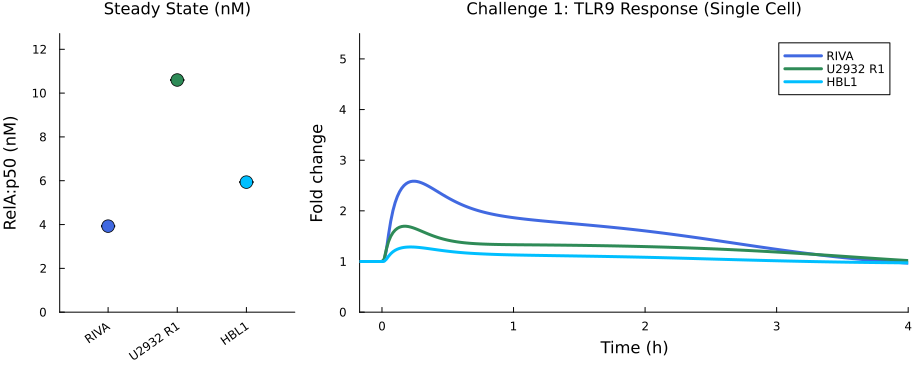

In [4]:
# Challenge 1: Remove the TAK1, MYD88, and CD79B mutations below to test expression differences alone!
pop1 = make_cell_population(1; cv=0.0)

c1_riva = simulate_condition(pop1; param_scales=Dict("k1_RelASynth-NFkB" => 0.4), bcr_ss=bcrSS, bcr_tc=bcrSS)

# Currently still includes the mutations — remove k1_Tp0-BCR, k1_TRAF6..., k1_MYD88..., and set bcrSS!
c1_u2932_r1 = simulate_condition(pop1;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 2.0,
        "basal_RelBSynth-NFkB" => 2.75,
        "k1_Tp0-BCR" => 10.0,
        "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    ),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

c1_hbl1 = simulate_condition(pop1;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 0.6,
        "k1_MYD88SELFACTIVATION-TLR" => 10.0,
    ),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)

plot_figure5_style(
    ["RIVA", "U2932 R1", "HBL1"],
    [c1_riva, c1_u2932_r1, c1_hbl1],
    [:royalblue, :seagreen, :deepskyblue];
    ymax_fc = 5.5,
    title_right = "Challenge 1: TLR9 Response (Single Cell)",
)

````{admonition} Hint
:class: dropdown tip

- For `c1_u2932_r1`, keep only `"k1_RelASynth-NFkB" => 2.0` and `"basal_RelBSynth-NFkB" => 2.75`.
- For `c1_hbl1`, keep only `"k1_RelASynth-NFkB" => 0.6` and switch `bcr_ss = bcrSS, bcr_tc = bcrSS`.
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
pop1 = make_cell_population(1; cv=0.0)

c1_riva = simulate_condition(pop1; param_scales=Dict("k1_RelASynth-NFkB" => 0.4), bcr_ss=bcrSS, bcr_tc=bcrSS)

c1_u2932_r1 = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 2.0, "basal_RelBSynth-NFkB" => 2.75),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

c1_hbl1 = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

plot_figure5_style(
    ["RIVA", "U2932 R1 (no mut)", "HBL1 (no mut)"],
    [c1_riva, c1_u2932_r1, c1_hbl1],
    [:royalblue, :seagreen, :deepskyblue];
    ymax_fc = 5.5,
    title_right = "Without Mutations: Expression Alone Does Not Blunt TLR9",
)
```

Without the upstream mutations, **U2932 R1** actually produces a **>4× fold-change spike** (larger than RIVA!), and **HBL1** jumps to **~3×**. That demonstrates a key result of Jayawant *et al.* Figure 5: gene expression alone cannot explain the blunted TLR9 response — the upstream **`TAK1`**, **`CD79B`**, and **`MYD88`** mutations are what cause the desensitised signalling phenotype!
````

---

### Challenge 2: Dissect HBL1's Two Mutations (`MYD88` Only vs `CD79B` Only vs Both)

HBL1 carries **two** upstream mutations: `MYD88` (`k1_MYD88SELFACTIVATION-TLR × 10`) and `CD79B` (`bcrSSHigh`).

**Your task:** Add the two single-mutation conditions (`hbl1_myd88` and `hbl1_cd79b`) in the cell below to see how each mutation contributes on its own compared to having both together!

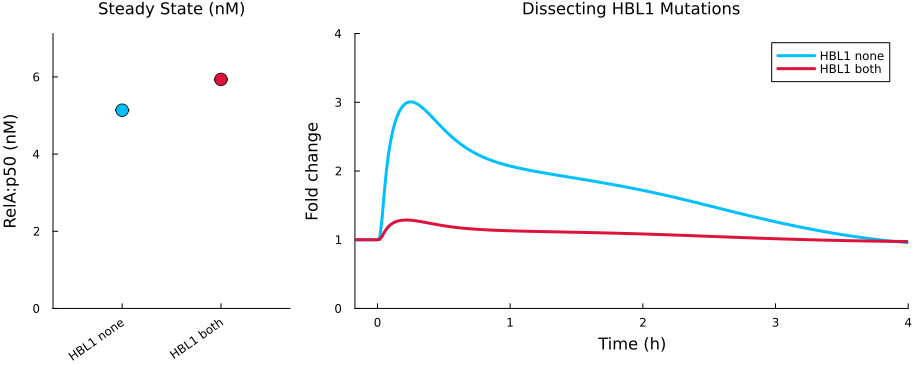

In [5]:
# Challenge 2: Compare HBL1 with no mutations, MYD88 only, CD79B only, and both!
hbl1_none = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

hbl1_both = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6, "k1_MYD88SELFACTIVATION-TLR" => 10.0),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)

# TODO: Add hbl1_myd88 (MYD88 only, bcrSS) and hbl1_cd79b (no MYD88, bcrSSHigh) and include them in the plot!
plot_figure5_style(
    ["HBL1 none", "HBL1 both"],
    [hbl1_none, hbl1_both],
    [:deepskyblue, :crimson];
    ymax_fc = 4.0,
    title_right = "Dissecting HBL1 Mutations",
)

````{admonition} Hint
:class: dropdown tip

Define:
```julia
hbl1_myd88 = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6, "k1_MYD88SELFACTIVATION-TLR" => 10.0),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

hbl1_cd79b = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)
```
and pass all four into `plot_figure5_style(...)`.
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
hbl1_none = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

hbl1_myd88 = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6, "k1_MYD88SELFACTIVATION-TLR" => 10.0),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

hbl1_cd79b = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)

hbl1_both = simulate_condition(pop1;
    param_scales = Dict("k1_RelASynth-NFkB" => 0.6, "k1_MYD88SELFACTIVATION-TLR" => 10.0),
    bcr_ss = bcrSSHigh, bcr_tc = bcrSSHigh)

plot_figure5_style(
    ["HBL1 none", "HBL1 +MYD88", "HBL1 +CD79B", "HBL1 both"],
    [hbl1_none, hbl1_myd88, hbl1_cd79b, hbl1_both],
    [:deepskyblue, :purple, :darkorange, :crimson];
    ymax_fc = 4.0,
    title_right = "Dissecting HBL1 Mutations (MYD88 vs CD79B)",
)
```

Both mutations act in the same direction, and combining **CD79B + MYD88** pushes resting `RelA:p50` highest and blunts the TLR9 fold-change most strongly — matching the experimental response of HBL1 cells in Jayawant *et al.* Figure 5.
````

---

### Challenge 3: Test a Targeted Inhibitor on `U2932 R1 (TAK1 mut)`

Now test an *in silico* drug on `U2932 R1 (TAK1 mut)` by changing a single parameter at run-time!
Suppose a drug accelerates IKK inactivation (`"k1_IKKdeg-linking" => 3.0`) — or directly inhibits the mutant TAK1 pathway (scaling `"k1_Tp0-BCR"` and `"k1_TRAF6mediatedIKKK_offactivation-TLR"` back down).

**Your task:** Edit `drug_scales` below to test an IKK or TAK1 inhibitor on `U2932 R1 (TAK1 mut)` and see how it shifts both resting `RelA:p50` and TLR9 fold change!

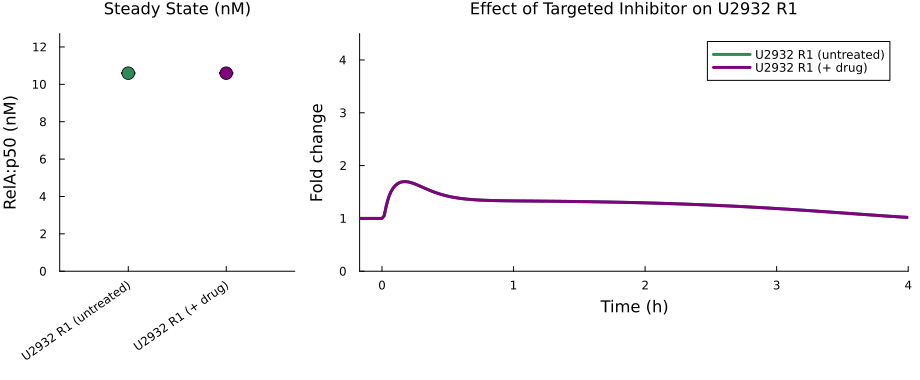

In [6]:
# Challenge 3: Edit drug_scales below (e.g. add "k1_IKKdeg-linking" => 3.0) to test a drug on U2932 R1!
u2932_untreated = simulate_condition(pop1;
    param_scales = Dict(
        "k1_RelASynth-NFkB" => 2.0,
        "basal_RelBSynth-NFkB" => 2.75,
        "k1_Tp0-BCR" => 10.0,
        "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    ),
    bcr_ss = bcrSS, bcr_tc = bcrSS)

drug_scales = Dict(
    "k1_RelASynth-NFkB" => 2.0,
    "basal_RelBSynth-NFkB" => 2.75,
    "k1_Tp0-BCR" => 10.0,
    "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    "k1_IKKdeg-linking" => 1.0,   # <-- Change 1.0 to 3.0 (or 5.0) to simulate an IKK inhibitor!
)

u2932_treated = simulate_condition(pop1; param_scales=drug_scales, bcr_ss=bcrSS, bcr_tc=bcrSS)

plot_figure5_style(
    ["U2932 R1 (untreated)", "U2932 R1 (+ drug)"],
    [u2932_untreated, u2932_treated],
    [:seagreen, :purple];
    ymax_fc = 4.5,
    title_right = "Effect of Targeted Inhibitor on U2932 R1",
)

````{admonition} Hint
:class: dropdown tip

Change `"k1_IKKdeg-linking" => 1.0` to `"k1_IKKdeg-linking" => 3.0` (or try reducing `"k1_Tp0-BCR"` and `"k1_TRAF6mediatedIKKK_offactivation-TLR"` from `10.0` to `1.0` to mimic a direct TAK1 inhibitor) and compare the resting steady state!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
drug_scales = Dict(
    "k1_RelASynth-NFkB" => 2.0,
    "basal_RelBSynth-NFkB" => 2.75,
    "k1_Tp0-BCR" => 10.0,
    "k1_TRAF6mediatedIKKK_offactivation-TLR" => 10.0,
    "k1_IKKdeg-linking" => 3.0,
)

u2932_treated = simulate_condition(pop1; param_scales=drug_scales, bcr_ss=bcrSS, bcr_tc=bcrSS)

plot_figure5_style(
    ["U2932 R1 (untreated)", "U2932 R1 (+ IKK inh)"],
    [u2932_untreated, u2932_treated],
    [:seagreen, :purple];
    ymax_fc = 4.5,
    title_right = "IKK Inhibition Reduces Basal RelA:p50 in U2932 R1",
)
```
````

---

## Summary

Across Tutorials 1 to 4, you have progressed from a 3-protein Toy Model all the way to reproducing published multi-module lymphoma simulations from **Jayawant *et al.* Figure 5**:
- Combining modular pathways (`BCR`, `TLR`, `NFkB`, and `linking`) with `combineModels.jl` and `CSV2Julia` in `param` mode.
- Setting conserved upstream protein pools and stiff ODE solver options (`FBDF` + `tstops`).
- Simulating heterogeneous cell populations (`preCV = 0.11` across `distribute == 1` parameters) and plotting steady-state error bars alongside fold-change time courses.
- Dissecting how gene expression scaling (`RelA`/`RelB`) and upstream mutations (`TAK1`, `CD79B`, `MYD88`) shape lymphoma signalling and drug responses.

:::{tip} Next Up (Tutorial 5)
Continue to **[Tutorial 5: Apoptosis Timing & Scanning BCL2 (Norris *et al.* Figure 1B)](../tutorial-5/01-apoptosis-bcl2-figure1b.ipynb)** to model cell death (**BCL2**) and cell division (**c-MYC**) timing in preparation for multiscale modelling.
:::